# 3. Modeling

Each stage adds one kind of information and is evaluated the same way, so improvements can be attributed. Models are tuned and early-stopped on the **validation** set only; the **test** set is scored once per row and never used to choose anything.

In [1]:
import sys
sys.path.insert(0, "../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import features as F

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

import experiments as E
from sklearn.metrics import roc_curve, roc_auc_score
rows = E.run_all()   # cached after the first run; delete data/cache/stage_*.pkl to retrain

In [2]:
table = pd.DataFrame(
    [{"model": label, "features": r.get("n_features", "17"), "validation AUC": r["val_auc"], "test AUC": r["test_auc"]}
     for label, stage, r in rows]
).set_index("model")
table.round(4)

,features,validation AUC,test AUC
model,,,
"Decision tree, depth 4 (original baseline)",17,0.6222,0.6244
"CatBoost, original settings (original baseline)",17,0.6773,0.6795
Original 17 hand-picked features,17,0.6762,0.6768
+ all application columns (no gender),119,0.7592,0.7576
+ engineered ratios and fixes,133,0.7686,0.7653
"+ bureau, installment and credit-card history",156,0.7825,0.7798


The first two rows are the original version of this project. Row three keeps the same 17 features but uses the improved CatBoost settings (deeper trees, lower learning rate, early stopping), so the gap between rows 2 and 3 is *model settings* and the gaps after that are *information*.

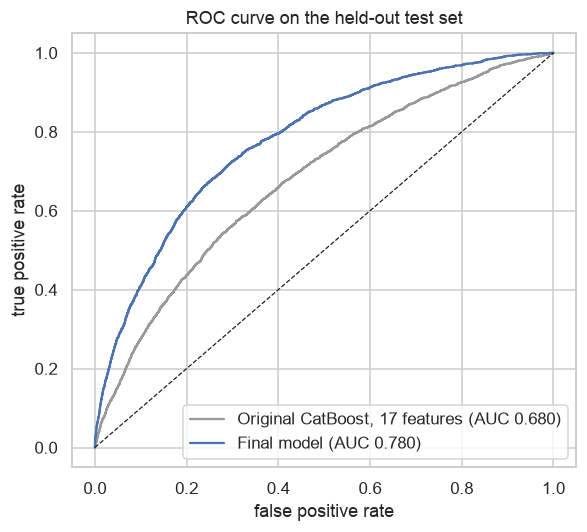

In [3]:
final = rows[-1][2]
base = rows[1][2]
fig, ax = plt.subplots(figsize=(5.5, 5))
for label, r, color in [("Original CatBoost, 17 features", base, "#999999"), ("Final model", final, "#4c72b0")]:
    fpr, tpr, _ = roc_curve(r["y_test"], r["pred_test"])
    ax.plot(fpr, tpr, color=color, label=f"{label} (AUC {r['test_auc']:.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=0.8); ax.set_xlabel("false positive rate"); ax.set_ylabel("true positive rate")
ax.set_title("ROC curve on the held-out test set"); ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig("../reports/roc_curve.png"); plt.show()

## What the final model relies on

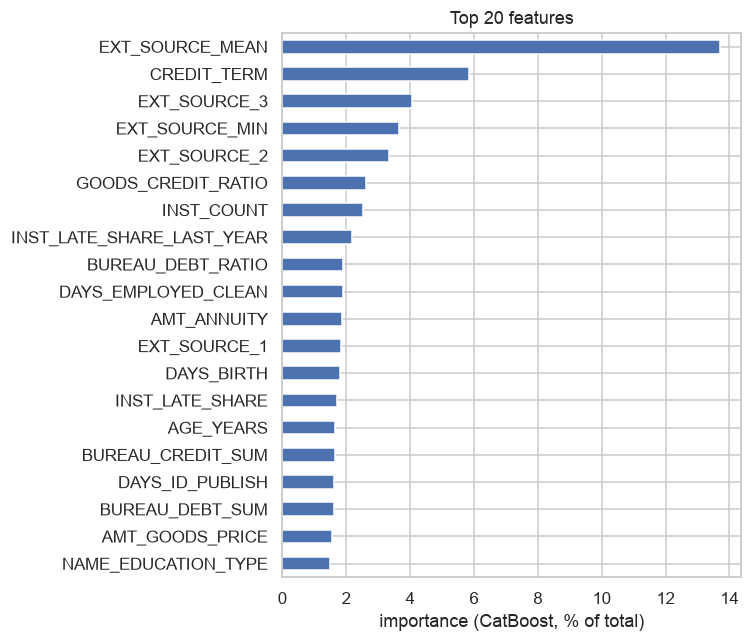

In [4]:
imp = pd.Series(final["importance"]).sort_values(ascending=False).head(20)
fig, ax = plt.subplots(figsize=(7, 6))
imp.iloc[::-1].plot.barh(ax=ax, color="#4c72b0"); ax.set_xlabel("importance (CatBoost, % of total)")
ax.set_title("Top 20 features"); plt.tight_layout(); plt.savefig("../reports/feature_importance.png"); plt.show()

## Does ranking by predicted risk work?

Sorting the test set into ten equal groups by predicted risk, the observed default rate should climb steadily.

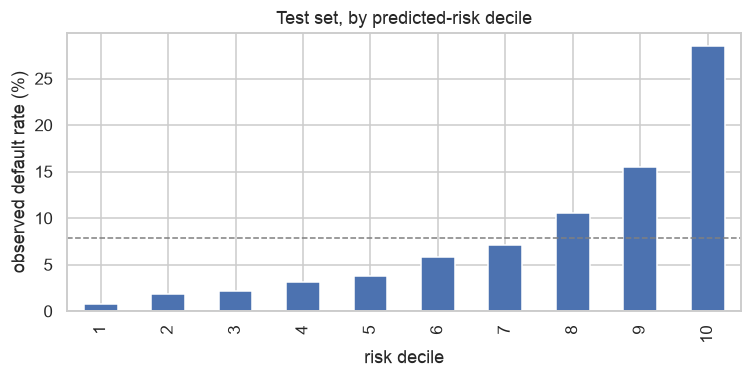

The riskiest decile defaults 3.6x as often as average; the safest decile 0.7%.


In [5]:
test_df = pd.DataFrame({"y": final["y_test"], "p": final["pred_test"]})
test_df["risk decile"] = pd.qcut(test_df["p"], 10, labels=range(1, 11))
dec = test_df.groupby("risk decile", observed=True).agg(**{"default rate (%)": ("y", lambda s: s.mean() * 100), "customers": ("y", "size")})
fig, ax = plt.subplots(figsize=(7, 3.6))
dec["default rate (%)"].plot.bar(ax=ax, color="#4c72b0"); ax.axhline(test_df.y.mean() * 100, color="gray", ls="--", lw=1)
ax.set_ylabel("observed default rate (%)"); ax.set_title("Test set, by predicted-risk decile"); plt.tight_layout(); plt.show()
top = dec.iloc[-1]["default rate (%)"] / (test_df.y.mean() * 100)
print(f"The riskiest decile defaults {top:.1f}x as often as average; the safest decile {dec.iloc[0]['default rate (%)']:.1f}%.")

## Gender: what is the cost of leaving it out?

The models above exclude `CODE_GENDER`. Using it would be discriminatory in real lending in many jurisdictions, so the question is how much predictive power that choice costs.

In [6]:
with_gender = E.run_stage("S4", E.FINAL_PARAMS, "S4_with_gender", drop_sensitive=False)
print(f"test AUC without gender: {final['test_auc']:.4f}")
print(f"test AUC with gender:    {with_gender['test_auc']:.4f}  (difference {with_gender['test_auc'] - final['test_auc']:+.4f})")

test AUC without gender: 0.7798
test AUC with gender:    0.7800  (difference +0.0002)


## Limitations and next steps

- **Selection bias.** The data only contains people who were approved. Applicants who were rejected never got a label, so the model says nothing about them.
- **Arbitrary hold-out.** The test split is by ID, not by time (see notebook 1). A real validation would be out-of-time.
- **No decision rule.** AUC measures ranking, not business value. Choosing a cutoff needs the cost of a default versus the profit from a good loan.
- **Not fully tuned.** Hyperparameters were set once and early-stopped, not searched.
- **Unused tables.** `previous_application`, `POS_CASH_balance` and `bureau_balance` from the competition are not used here and hold more signal.
- **Fairness.** Dropping gender does not remove proxies for it (occupation, region, income type). A proper fairness review would measure error rates across groups.